# CitizenTech — Alerta de calor extremo em São Paulo (IA & Machine Learning)

**Pergunta de ML:** dadas as condições meteorológicas observadas **hoje** na estação INMET A701 (Mirante de Santana, São Paulo), amanhã vai haver **calor extremo** (temperatura máxima ≥ 35 °C)?

- **Tipo de problema:** classificação binária (evento raro → classes desbalanceadas)
- **Modelo:** Random Forest
- **Fonte dos dados:** INMET, dados históricos horários da estação automática A701 (https://portal.inmet.gov.br/dadoshistoricos). Dados reais, sem simulação.
- **Divisão:** temporal (treino = anos antigos, teste = anos mais recentes)
- **Validação cruzada:** `TimeSeriesSplit`, somente dentro do treino
- **Ligação com o projeto:** o limiar de 35 °C é o mesmo nível de *Atenção* para calor extremo da API em C# e do circuito ESP32 da CitizenTech.


In [1]:
import io, os, time, zipfile, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import requests
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.metrics import (precision_score, recall_score, f1_score, average_precision_score,
                             roc_auc_score, confusion_matrix, precision_recall_curve)
warnings.filterwarnings("ignore")
RANDOM_STATE = 42

# ---------------- Configuração ----------------
ESTACAO = "A701"                 # São Paulo - Mirante de Santana (INMET)
ANOS = list(range(2013, 2026))   # período usado
ANO_INICIO_TESTE = 2023          # treino: < 2023 | teste: >= 2023
LIMIAR_CALOR_C = 35.0            # calor extremo = temperatura máxima do dia >= 35 °C
RAW_DIR = "dados/raw"
os.makedirs(RAW_DIR, exist_ok=True)
os.makedirs("figuras", exist_ok=True)

## 1. Problema e dados reais

Fonte: **INMET – Banco de Dados Históricos**, arquivos anuais `AAAA.zip` com um CSV por estação (dados horários).
Link: https://portal.inmet.gov.br/dadoshistoricos · Estação: **A701 – São Paulo/Mirante de Santana** · Período: conforme `ANOS` acima.

Limitação assumida: uma única estação representa a cidade inteira, e a temperatura máxima é obtida dos registros horários.

In [2]:
def baixar_ano(ano, tentativas=6):
    # Baixa o zip do INMET com novas tentativas (o servidor às vezes derruba a conexão).
    destino = f"{RAW_DIR}/{ano}.zip"
    if os.path.exists(destino) and zipfile.is_zipfile(destino):
        return destino                                  # já baixado antes: reaproveita
    url = f"https://portal.inmet.gov.br/uploads/dadoshistoricos/{ano}.zip"
    for t in range(1, tentativas + 1):
        try:
            print(f"baixando {url} (tentativa {t})")
            with requests.get(url, timeout=(30, 300), stream=True,
                              headers={"User-Agent": "Mozilla/5.0"}) as r:
                r.raise_for_status()
                with open(destino + ".part", "wb") as f:
                    for bloco in r.iter_content(chunk_size=1024 * 1024):
                        f.write(bloco)
            os.replace(destino + ".part", destino)
            if not zipfile.is_zipfile(destino):
                raise OSError("arquivo baixado não é um zip válido")
            time.sleep(2)                               # pausa curta entre downloads
            return destino
        except (requests.exceptions.RequestException, OSError) as e:
            print("  falhou:", type(e).__name__)
            for p in (destino, destino + ".part"):
                if os.path.exists(p) and not zipfile.is_zipfile(p):
                    os.remove(p)
            time.sleep(5 * t)                           # espera cada vez maior
    raise RuntimeError(f"Não foi possível baixar {url}. Rode a célula de novo em alguns minutos.")

def ler_estacao(zip_path, estacao):
    with zipfile.ZipFile(zip_path) as z:
        nomes = [n for n in z.namelist() if f"_{estacao}_" in n.upper()]
        if not nomes:
            raise FileNotFoundError(f"{estacao} não encontrada em {zip_path}")
        bruto = z.read(nomes[0])
    df = pd.read_csv(io.BytesIO(bruto), sep=";", skiprows=8, encoding="latin-1",
                     decimal=",", na_values=["-9999", "-9999,0"], index_col=False)
    df = df.loc[:, ~df.columns.str.startswith("Unnamed")]
    return df

def achar(df, *palavras):
    for c in df.columns:
        cu = c.upper()
        if all(p in cu for p in palavras):
            return c
    return None

def padronizar(df):
    col_data, col_hora = df.columns[0], df.columns[1]
    hora = df[col_hora].astype(str).str.extract(r"(\d{2}):?(\d{2})")
    ts = pd.to_datetime(df[col_data].astype(str).str.replace("/", "-") + " " + hora[0] + ":" + hora[1],
                        errors="coerce")
    ts = ts.dt.tz_localize("UTC").dt.tz_convert("America/Sao_Paulo").dt.tz_localize(None)
    mapa = {
        "chuva": achar(df, "PRECIPITA"),
        "pressao": achar(df, "PRESS", "ESTA"),
        "temp": achar(df, "TEMPERATURA DO AR"),
        "temp_max_hora": achar(df, "TEMPERATURA M", "XIMA"),
        "umid": achar(df, "UMIDADE RELATIVA DO AR"),
        "vento": achar(df, "VENTO, VELOCIDADE"),
        "radiacao": achar(df, "RADIACAO"),
    }
    out = pd.DataFrame({"ts": ts})
    for k, c in mapa.items():
        out[k] = pd.to_numeric(df[c], errors="coerce") if c else np.nan
    # Se a coluna de máxima horária não existir, usa a temperatura instantânea.
    out["temp_max_hora"] = out["temp_max_hora"].fillna(out["temp"])
    return out.dropna(subset=["ts"])

horario = pd.concat([padronizar(ler_estacao(baixar_ano(a), ESTACAO)) for a in ANOS], ignore_index=True)
horario = horario.sort_values("ts").drop_duplicates("ts")
print(horario.shape, horario.ts.min(), "->", horario.ts.max())
horario.head()

baixando https://portal.inmet.gov.br/uploads/dadoshistoricos/2013.zip (tentativa 1)
baixando https://portal.inmet.gov.br/uploads/dadoshistoricos/2014.zip (tentativa 1)
baixando https://portal.inmet.gov.br/uploads/dadoshistoricos/2015.zip (tentativa 1)
baixando https://portal.inmet.gov.br/uploads/dadoshistoricos/2016.zip (tentativa 1)
baixando https://portal.inmet.gov.br/uploads/dadoshistoricos/2017.zip (tentativa 1)
baixando https://portal.inmet.gov.br/uploads/dadoshistoricos/2018.zip (tentativa 1)
baixando https://portal.inmet.gov.br/uploads/dadoshistoricos/2019.zip (tentativa 1)
baixando https://portal.inmet.gov.br/uploads/dadoshistoricos/2020.zip (tentativa 1)
baixando https://portal.inmet.gov.br/uploads/dadoshistoricos/2021.zip (tentativa 1)
baixando https://portal.inmet.gov.br/uploads/dadoshistoricos/2022.zip (tentativa 1)
baixando https://portal.inmet.gov.br/uploads/dadoshistoricos/2023.zip (tentativa 1)
baixando https://portal.inmet.gov.br/uploads/dadoshistoricos/2024.zip (tenta

,ts,chuva,pressao,temp,temp_max_hora,umid,vento,radiacao
0,2012-12-31 22:00:00,0.0,925.7,24.8,25.4,71.0,2.4,NaN
1,2012-12-31 23:00:00,0.0,925.9,24.2,24.8,70.0,0.3,NaN
2,2013-01-01 00:00:00,0.0,924.6,23.4,24.3,66.0,2.2,NaN
3,2013-01-01 01:00:00,0.0,924.4,22.1,23.4,74.0,2.4,NaN
4,2013-01-01 02:00:00,0.0,923.7,22.5,22.5,73.0,1.1,NaN


## 2. Preparação dos dados (limpeza, atributos, alvo e divisão treino/teste)

- Hora UTC convertida para horário de Brasília.
- Agregação **diária**: temperatura máxima, mínima e média, amplitude, umidade (média e mínima), pressão (e variação), vento, chuva e radiação.
- Atributos de memória: temperatura máxima dos 1, 2 e 3 dias anteriores, média móvel de 3 dias e sazonalidade (mês em seno/cosseno).
- **Alvo:** `calor_extremo_amanha = 1` se a temperatura máxima do dia seguinte for ≥ `LIMIAR_CALOR_C`.
- Dias sem observação suficiente (< 20 horas válidas) são descartados.
- Valores faltantes são preenchidos com a **mediana calculada só no treino** (evita vazamento de dados).

In [3]:
h = horario.copy()
h["data"] = h.ts.dt.floor("D")
g = h.groupby("data")
dia = pd.DataFrame({
    "horas_validas": g.temp.count(),
    "temp_max": g.temp_max_hora.max(),
    "temp_min": g.temp.min(),
    "temp_media": g.temp.mean(),
    "umid_media": g.umid.mean(),
    "umid_min": g.umid.min(),
    "pressao_media": g.pressao.mean(),
    "vento_medio": g.vento.mean(),
    "chuva_total": g.chuva.sum(min_count=1),
    "radiacao_max": g.radiacao.max(),
})
dia = dia[dia.horas_validas >= 20].asfreq("D")        # dias faltantes viram NaN
dia["amplitude"] = dia.temp_max - dia.temp_min
dia["var_pressao"] = dia.pressao_media.diff()
for lag in (1, 2, 3):
    dia[f"temp_max_lag{lag}"] = dia.temp_max.shift(lag)
dia["temp_max_media3d"] = dia.temp_max.rolling(3, min_periods=2).mean()
dia["mes_sin"] = np.sin(2*np.pi*dia.index.month/12)
dia["mes_cos"] = np.cos(2*np.pi*dia.index.month/12)

proxima_tmax = dia.temp_max.shift(-1)
dia["calor_extremo_amanha"] = (proxima_tmax >= LIMIAR_CALOR_C).astype(float)
dia.loc[proxima_tmax.isna(), "calor_extremo_amanha"] = np.nan

ATRIBUTOS = [c for c in dia.columns if c not in ("horas_validas", "calor_extremo_amanha")]
if dia.radiacao_max.notna().mean() < 0.5:        # radiação ausente na maior parte do período
    ATRIBUTOS.remove("radiacao_max")
    print("Radiação com muitos valores ausentes: atributo removido.")

dados = dia.dropna(subset=["calor_extremo_amanha"]).copy()
treino = dados[dados.index.year < ANO_INICIO_TESTE].copy()
teste = dados[dados.index.year >= ANO_INICIO_TESTE].copy()

medianas = treino[ATRIBUTOS].median()                 # só do treino
treino[ATRIBUTOS] = treino[ATRIBUTOS].fillna(medianas)
teste[ATRIBUTOS] = teste[ATRIBUTOS].fillna(medianas)
pd.concat([treino, teste]).to_csv("dados/inmet_a701_diario_processado.csv")

X_tr, y_tr = treino[ATRIBUTOS], treino.calor_extremo_amanha.astype(int)
X_te, y_te = teste[ATRIBUTOS], teste.calor_extremo_amanha.astype(int)
print(f"Dias úteis: {len(dados)} | treino: {len(treino)} | teste: {len(teste)}")
print(f"Eventos de calor extremo (>= {LIMIAR_CALOR_C} °C): treino {y_tr.sum()} ({y_tr.mean():.1%}) | teste {y_te.sum()} ({y_te.mean():.1%})")

Dias úteis: 4711 | treino: 3633 | teste: 1078
Eventos de calor extremo (>= 35.0 °C): treino 41 (1.1%) | teste 18 (1.7%)


## 3. Escolha justificada do modelo

Usamos **Random Forest** porque: (i) lida bem com dados tabulares e relações não lineares entre temperatura, umidade e pressão; (ii) é robusto a atributos em escalas diferentes (sem normalização); (iii) aceita `class_weight="balanced"` para o evento raro; (iv) fornece a importância dos atributos, útil para explicar o alerta ao cidadão.

## 4. Treino com diferentes hiperparâmetros

Busca aleatória com **15 combinações** de **3 hiperparâmetros** (`n_estimators`, `max_depth`, `min_samples_leaf`), validação cruzada `TimeSeriesSplit(5)` **apenas no treino** e métrica **PR-AUC (average precision)**, adequada a evento raro. Como o calor extremo é sazonal e raro, descartamos as divisões em que o bloco de validação ou o de treino não tem nenhum evento (a PR-AUC não existe sem exemplos positivos).

In [4]:
todas = list(TimeSeriesSplit(n_splits=5).split(X_tr))
divisoes = [(a, b) for a, b in todas if y_tr.iloc[b].sum() > 0 and y_tr.iloc[a].sum() > 0]
print(f"Divisões de validação cruzada usadas: {len(divisoes)} de {len(todas)}")

espaco = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [3, 5, 8, 12, None],
    "min_samples_leaf": [1, 3, 5, 10, 20],
}
busca = RandomizedSearchCV(
    RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
    param_distributions=espaco, n_iter=15,
    cv=divisoes, scoring="average_precision",
    random_state=RANDOM_STATE, return_train_score=True, n_jobs=-1, refit=True)
busca.fit(X_tr, y_tr)

res = pd.DataFrame(busca.cv_results_)
cols = ["param_n_estimators", "param_max_depth", "param_min_samples_leaf",
        "mean_train_score", "mean_test_score", "std_test_score", "rank_test_score"]
res = res[cols].sort_values("rank_test_score")
res.columns = ["n_estimators", "max_depth", "min_samples_leaf", "PR-AUC treino (CV)", "PR-AUC validação (CV)", "desvio", "ranking"]
print("Melhores hiperparâmetros:", busca.best_params_)
res.round(3)

Divisões de validação cruzada usadas: 5 de 5
Melhores hiperparâmetros: {'n_estimators': 100, 'min_samples_leaf': 1, 'max_depth': 3}


,n_estimators,max_depth,min_samples_leaf,PR-AUC treino (CV),PR-AUC validação (CV),desvio,ranking
9,100,3,1,0.758,0.390,0.233,1
6,300,5,1,0.880,0.388,0.223,2
5,500,5,20,0.696,0.383,0.216,3
13,200,5,10,0.774,0.380,0.218,4
4,100,8,3,0.939,0.379,0.217,5
1,200,8,10,0.799,0.378,0.217,6
12,200,12,10,0.802,0.377,0.215,7
10,300,3,20,0.648,0.376,0.219,8
2,300,12,5,0.914,0.374,0.207,9
14,300,None,5,0.916,0.374,0.207,10


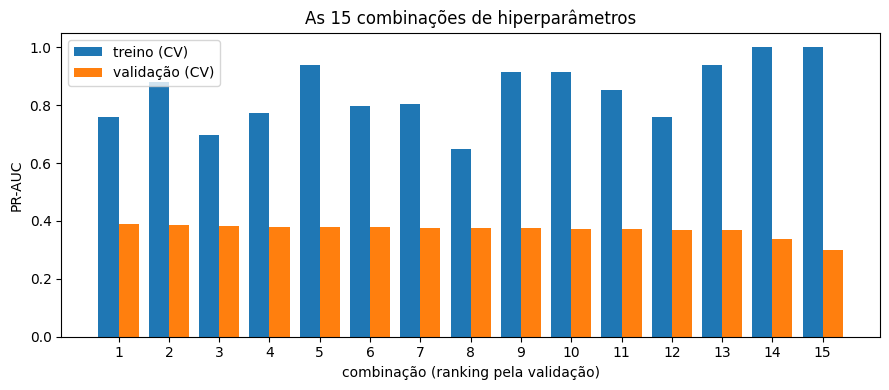

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
r = res.sort_values("ranking")
x = np.arange(len(r))
ax.bar(x - 0.2, r["PR-AUC treino (CV)"], 0.4, label="treino (CV)")
ax.bar(x + 0.2, r["PR-AUC validação (CV)"], 0.4, label="validação (CV)")
ax.set_xticks(x); ax.set_xticklabels(r["ranking"].astype(int))
ax.set_xlabel("combinação (ranking pela validação)"); ax.set_ylabel("PR-AUC")
ax.set_title("As 15 combinações de hiperparâmetros"); ax.legend(); plt.tight_layout()
plt.savefig("figuras/grafico_hiperparametros.png", dpi=150)
plt.show()

## 5. Limiar de decisão (escolhido só com o treino)

O limiar padrão de 0,5 não é o ideal para um evento raro. Escolhemos o limiar que maximiza o **F1** usando as previsões *fora da amostra* da validação cruzada, ou seja, **sem olhar para o teste**.

In [6]:
from sklearn.base import clone
oof_y, oof_p = [], []
for a, b in divisoes:
    m = clone(busca.best_estimator_).fit(X_tr.iloc[a], y_tr.iloc[a])
    oof_p.extend(m.predict_proba(X_tr.iloc[b])[:, 1]); oof_y.extend(y_tr.iloc[b])
oof_y, oof_p = np.array(oof_y), np.array(oof_p)
candidatos = np.linspace(0.05, 0.95, 91)
f1s = [f1_score(oof_y, (oof_p >= t).astype(int), zero_division=0) for t in candidatos]
LIMIAR_DECISAO = float(candidatos[int(np.argmax(f1s))])
print(f"Limiar de decisão escolhido (F1 máximo na validação cruzada): {LIMIAR_DECISAO:.2f}")

Limiar de decisão escolhido (F1 máximo na validação cruzada): 0.60


## 6. Resultados em treino e teste

In [7]:
modelo = busca.best_estimator_
def metricas(X, y, limiar):
    p = modelo.predict_proba(X)[:, 1]; yhat = (p >= limiar).astype(int)
    return {"Precisão": precision_score(y, yhat, zero_division=0), "Recall": recall_score(y, yhat),
            "F1": f1_score(y, yhat), "PR-AUC": average_precision_score(y, p), "ROC-AUC": roc_auc_score(y, p)}, p, yhat

m_tr, p_tr, yh_tr = metricas(X_tr, y_tr, LIMIAR_DECISAO)
m_te, p_te, yh_te = metricas(X_te, y_te, LIMIAR_DECISAO)
m_tr5, _, _ = metricas(X_tr, y_tr, 0.5)
m_te5, _, yh_te5 = metricas(X_te, y_te, 0.5)

print("Linha de base (prevalência no teste):", round(y_te.mean(), 3))
print(f"\nResultados com o limiar escolhido ({LIMIAR_DECISAO:.2f}):")
tabela = pd.DataFrame({"Treino": m_tr, "Teste": m_te}).round(3)
display(tabela)
print("Para comparação, com o limiar padrão 0,5:")
display(pd.DataFrame({"Treino": m_tr5, "Teste": m_te5}).round(3))

Linha de base (prevalência no teste): 0.017

Resultados com o limiar escolhido (0.60):


,Treino,Teste
Precisão,0.231,0.203
Recall,0.829,0.722
F1,0.362,0.317
PR-AUC,0.583,0.458
ROC-AUC,0.987,0.976


Para comparação, com o limiar padrão 0,5:


,Treino,Teste
Precisão,0.175,0.188
Recall,0.927,1.000
F1,0.295,0.316
PR-AUC,0.583,0.458
ROC-AUC,0.987,0.976


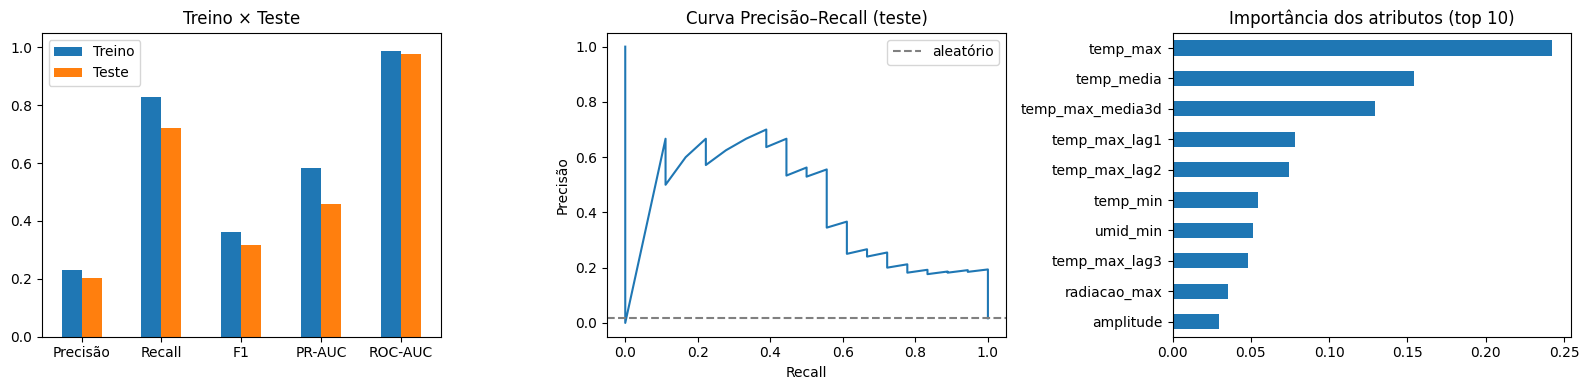

Matriz de confusão (teste) [linhas = real, colunas = previsto]:
 [[1009   51]
 [   5   13]]
Alarmes emitidos: 64 | acertos: 13 | alarmes falsos: 51 | eventos perdidos: 5
Dias do teste: 1078 | dias com alarme: 64 (5.9%)


In [8]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4))
tabela.plot.bar(ax=axs[0], rot=0); axs[0].set_title("Treino × Teste"); axs[0].set_ylim(0, 1.05)
pr, rc, _ = precision_recall_curve(y_te, p_te)
axs[1].plot(rc, pr); axs[1].axhline(y_te.mean(), ls="--", c="gray", label="aleatório")
axs[1].set_xlabel("Recall"); axs[1].set_ylabel("Precisão"); axs[1].set_title("Curva Precisão–Recall (teste)"); axs[1].legend()
imp = pd.Series(modelo.feature_importances_, index=ATRIBUTOS).sort_values().tail(10)
imp.plot.barh(ax=axs[2]); axs[2].set_title("Importância dos atributos (top 10)")
plt.tight_layout()
plt.savefig("figuras/resultados_treino_teste.png", dpi=150)
plt.show()

cm = confusion_matrix(y_te, yh_te, labels=[0, 1])
print("Matriz de confusão (teste) [linhas = real, colunas = previsto]:\n", cm)
print(f"Alarmes emitidos: {cm[:,1].sum()} | acertos: {cm[1,1]} | alarmes falsos: {cm[0,1]} | eventos perdidos: {cm[1,0]}")
print(f"Dias do teste: {len(y_te)} | dias com alarme: {int(cm[:,1].sum())} ({cm[:,1].sum()/len(y_te):.1%})")

## 7. Discussão: overfitting

Compare, na tabela acima, as métricas de **treino** e **teste**: uma queda grande de treino para teste (principalmente em PR-AUC e F1) indica overfitting. Compare também a PR-AUC de treino e de validação na busca de hiperparâmetros (gráfico das 15 combinações). A interpretação, com os números desta execução, está em `RELATORIO_ML.md`.

## 8. O que o resultado significa para o cidadão

Para o alarme da CitizenTech, o trade-off é: **recall alto** significa poucas ondas de calor sem aviso; **precisão alta** significa poucos alarmes falsos (que fazem a população parar de confiar no aviso). Os números do teste acima dizem quantos alertas o sistema teria disparado, quantos foram reais e quantos eventos passaram sem aviso. Os pontos de segurança da CitizenTech (áreas refrigeradas, água mais barata) são fictícios no protótipo, mas o gatilho do alarme usa apenas dados reais.